In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import MinMaxScaler
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import LabelEncoder

from sklearn.impute import SimpleImputer

In [2]:
data = {
    "Age":[22,25,29,31,np.nan,40,35],
    "Salary":[35000,42000,50000,np.nan,58000,62000,72000],
    "Department":["IT","HR","IT","Finance","Finance","HR","IT"],
    "City":["NY","LA","NY","LA","NY","LA","NY"]
}

df = pd.DataFrame(data)

df

,Age,Salary,Department,City
0,22.0,35000.0,IT,NY
1,25.0,42000.0,HR,LA
2,29.0,50000.0,IT,NY
3,31.0,NaN,Finance,LA
4,NaN,58000.0,Finance,NY
5,40.0,62000.0,HR,LA
6,35.0,72000.0,IT,NY


#Exercise 1 — Handle Missing Values

* Replace missing values:

Age → median

Salary → mean

* Tasks:

```
1 Create SimpleImputer
2 Apply transformation
3 Print the cleaned dataframe
```

In [4]:
imputemed=SimpleImputer(strategy='median')
imputemean=SimpleImputer(strategy='mean')

df['Age']=imputemed.fit_transform(df[['Age']])
df['Salary']=imputemean.fit_transform(df[['Salary']])

df

,Age,Salary,Department,City
0,22.0,35000.000000,IT,NY
1,25.0,42000.000000,HR,LA
2,29.0,50000.000000,IT,NY
3,31.0,53166.666667,Finance,LA
4,30.0,58000.000000,Finance,NY
5,40.0,62000.000000,HR,LA
6,35.0,72000.000000,IT,NY


#Exercise 2 — Encode Department

Convert the Department column into numerical features using OneHotEncoding.

Expected output columns:
```
Department_IT
Department_HR
Department_Finance
```

In [7]:
df_encoded=pd.get_dummies(df,columns=['Department'],dtype=int)
df_encoded

,Age,Salary,City,Department_Finance,Department_HR,Department_IT
0,22.0,35000.000000,NY,0,0,1
1,25.0,42000.000000,LA,0,1,0
2,29.0,50000.000000,NY,0,0,1
3,31.0,53166.666667,LA,1,0,0
4,30.0,58000.000000,NY,1,0,0
5,40.0,62000.000000,LA,0,1,0
6,35.0,72000.000000,NY,0,0,1


#Exercise 3 — Feature Scaling

Scale the following columns using StandardScaler:

```
Age
Salary
```

Print the scaled dataframe.

In [10]:
scaler=StandardScaler()
df_scaled=pd.DataFrame(scaler.fit_transform(df_encoded[['Age','Salary']]), columns=['Age_scaled','Salary_scaled'])
df_scaled

,Age_scaled,Salary_scaled
0,-1.493576,-1.583922
1,-0.952798,-0.973603
2,-0.231762,-0.276096
3,0.128757,0.000000
4,-0.051503,0.421410
5,1.751089,0.770164
6,0.849793,1.642047


#Exercise 4 — Create a New Feature

Create a feature called:

```
Salary_per_Age
```
Formula:

```
Salary / Age
```

In [23]:
df['Salary_per_Age']=df['Salary']/df['Age']
df

,Age,Salary,Department,City,Salary_per_Age
0,22.0,35000.000000,IT,NY,1590.909091
1,25.0,42000.000000,HR,LA,1680.000000
2,29.0,50000.000000,IT,NY,1724.137931
3,31.0,53166.666667,Finance,LA,1715.053763
4,30.0,58000.000000,Finance,NY,1933.333333
5,40.0,62000.000000,HR,LA,1550.000000
6,35.0,72000.000000,IT,NY,2057.142857


#Exercise 5 — Data Exploration

Plot the distribution of Salary.

Use:

```
sns.histplot()
```

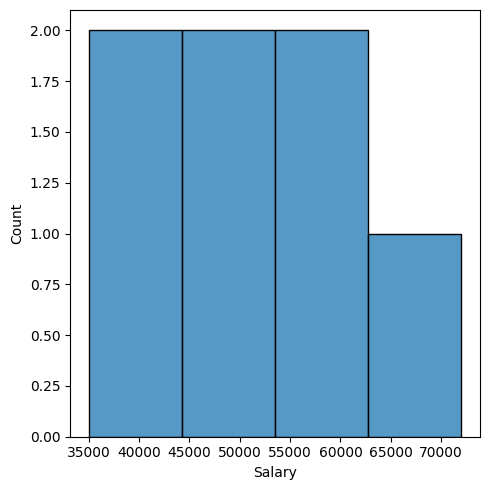

In [14]:
plt.figure(figsize=(5,5))
sns.histplot(df_encoded['Salary'])
plt.tight_layout()
plt.show()

#Exercise 6 — Feature Selection

Compute correlation matrix.

Steps:

```
1 Select numeric columns
2 Compute correlation
3 Plot heatmap
```
Hint:
```
sns.heatmap()
```

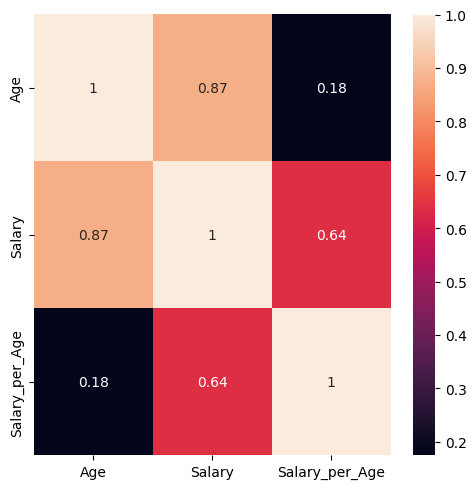

In [24]:
plt.figure(figsize=(5,5))
sns.heatmap(df.corr(numeric_only=True),annot=True)
plt.tight_layout()
plt.show()

#Exercise 7 — Build a Preprocessing Pipeline (Advanced)

Using sklearn Pipeline, combine:
```
Imputer
Scaling
```
Apply it to the numeric features.

In [21]:
from sklearn.pipeline import Pipeline

In [22]:
pipeline=Pipeline([
    ('imputer',SimpleImputer(strategy='median')),
    ('scaler',StandardScaler())
])

df_pipeline=pd.DataFrame(pipeline.fit_transform(df_encoded[['Age','Salary']]),columns=['Age_pipeline','Salary_pipeline'])
df_pipeline

,Age_pipeline,Salary_pipeline
0,-1.493576,-1.583922
1,-0.952798,-0.973603
2,-0.231762,-0.276096
3,0.128757,0.000000
4,-0.051503,0.421410
5,1.751089,0.770164
6,0.849793,1.642047


#Exercise 8 — Discussion Question

Answer:
```
Why is feature scaling important for clustering algorithms like KMeans?
```

In [ ]:
# algorithms like KMeans rely on distance calculations to group data points,
# without scaling, features with larger values (salary for example) can dominate the distance calculations,
# scaling ensures all features contribute more fairly to clustering.